# Separate longitudinal Master cohort: experience versus matchup

Shared experience is primary; grouped A–J/Unclassified is secondary. This notebook uses the existing Master-labeled longitudinal cohort, not historical Master/GM/Challenger OTP subsets. No cohort pooling or collection runs. Descriptive EDA is in [master_cohort_eda.ipynb](master_cohort_eda.ipynb).

The source is discovered and hash-verified through its preparation manifest. All Master labels are legacy seeds without dated rank verification; the benchmark is **Global Master+**, not exact Master. Prior notebooks already examined validation and test outcomes: this is an exposed retrospective reanalysis, not a fresh confirmatory test.

In [1]:
from pathlib import Path
import sys, json, importlib.metadata as metadata
import numpy as np
import pandas as pd
from IPython.display import display, Image
start=Path.cwd().resolve()
PROJECT_ROOT=next(p for p in [start,*start.parents] if (p/'hlr_model/master_cohort_modeling.py').is_file())
if str(PROJECT_ROOT) not in sys.path:sys.path.insert(0,str(PROJECT_ROOT))
from hlr_model import master_cohort_modeling as master
RUN_MODELING=True
CONFIG=master.Config(profile='full')
ENVIRONMENT={name:metadata.version(name) for name in ['numpy','pandas','scipy','scikit-learn','matplotlib','openpyxl','pyarrow','torch','pyro-ppl']}
assert ENVIRONMENT['pyro-ppl']=='1.9.2'
print('Actual notebook interpreter:',sys.executable)
print('Dependencies:',ENVIRONMENT)
print('Fitting enabled:',RUN_MODELING,'profile:',CONFIG.profile,CONFIG.sampling)


Actual notebook interpreter: /Users/minhho-hoang/Documents/riot_proj/riot-game-prediction/.venv-modeling/bin/python
Dependencies: {'numpy': '1.26.4', 'pandas': '2.2.3', 'scipy': '1.13.1', 'scikit-learn': '1.9.1', 'matplotlib': '3.9.2', 'openpyxl': '3.1.5', 'pyarrow': '17.0.0', 'torch': '2.15.0', 'pyro-ppl': '1.9.2'}
Fitting enabled: True profile: full {'chains': 4, 'warmup': 600, 'draws': 1200, 'max_tree_depth': 9, 'train_match_limit': None}


## 1. Offline source audit, histories and comparable partitions

Verify all source/output hashes, cached benchmark provenance and strictly prior completion times. The existing independent validator reconstructs candidate counts/wins and eligibility. Unplayed alternatives have no outcomes. Preserve the same two UTC boundaries, group shared matches, and purge unfinished boundary matches. Missing benchmarks and incomplete history are explicit exclusions; genuinely short complete histories are retained.

In [2]:
prepared,groups,study_rows,study_metadata,audit=master.prepare(PROJECT_ROOT,CONFIG)
SUPPORT=master.support_tables(prepared)
display(pd.Series({k:audit[k] for k in ['selected_players','target_players','usable_source_players','target_rows','target_unique_matches','candidate_rows','unplayed_alternatives','dated_rank_verified_players','prior_outcome_exposure']}))
display(SUPPORT['split_support']);display(SUPPORT['usable_split_support']);display(SUPPORT['exclusions'])
display(SUPPORT['training_support']);display(SUPPORT['training_group_support'])
print('Source:',audit['longitudinal_snapshot'],'Benchmark:',audit['benchmark_run'])
print('Initial history of players with targets:',audit['initial_history_actual_target_players'])
print('Prior analyses:',audit['prior_analysis'])

print('Unplayed alternative coverage/exclusions:')
display(prepared['alternatives'].groupby('data_exclusion_reasons').agg(rows=('match_id','size'),players=('puuid','nunique'),matches=('match_id','nunique')))


selected_players                 200
target_players                   185
usable_source_players            184
target_rows                     7238
target_unique_matches           6806
candidate_rows                 83523
unplayed_alternatives          76285
dated_rank_verified_players        0
prior_outcome_exposure          True
dtype: object

,split,rows,players,matches,usable_rows
0,purged_train_boundary,11,11,11,11
1,purged_validation_boundary,16,16,16,16
2,test,1067,128,1021,1065
3,train,5095,178,4753,5086
4,validation,1049,128,1005,1049


,split,rows,players,matches
0,test,1065,127,1019
1,train,5086,177,4746
2,validation,1049,128,1005


,split,data_exclusion_reasons,rows
0,purged_train_boundary,none,11
1,purged_validation_boundary,none,16
2,test,incomplete_initial_history,1
3,test,none,1065
4,test,unidentified_lane_opponent|missing_or_unverifi...,1
5,train,incomplete_initial_history,4
6,train,missing_or_unverified_global_matchup,2
7,train,none,5086
8,train,unidentified_lane_opponent|missing_or_unverifi...,3
9,validation,none,1049


,training_games,players,player_champions,median_games_per_pc,fraction_pc_once,fraction_pc_lt5,players_n_ge50,players_n_ge100
0,5086,177,1388,1.0,0.554755,0.829251,111,65


,mastery_group,games,players,champions,median_experience,players_n_ge50,players_n_ge100
0,A,408,61,16,22.5,10,6
1,B,478,64,16,39.5,13,10
2,C,322,84,15,13.0,10,4
3,D,695,90,15,58.0,14,5
4,E,427,87,16,10.0,8,5
5,F,630,93,15,54.0,20,11
6,G,371,79,16,21.0,8,6
7,H,495,86,16,27.0,12,8
8,I,344,68,16,17.0,10,4
9,J,580,94,20,28.0,11,6


Source: hlr_model/data/runs/patch_16_19_seed_1619/processed/20261018T195205790466Z Benchmark: hlr_model/data/lolalytics/runs/20261020T164500_repaired
Initial history of players with targets: {'count': 185.0, 'mean': 161.56216216216217, 'std': 24.933774799144075, 'min': 46.0, '25%': 170.0, '50%': 170.0, '75%': 170.0, 'max': 170.0}
Prior analyses: [{'notebook': 'hlr_modeling.ipynb', 'sha256': 'b70a13b7098c684bfdb57b5fa517dfa596aea231977efad2e2f2f02a60ec49e6', 'executed_outcome_analysis_cells': [7, 14]}, {'notebook': 'tradeoff_modeling.ipynb', 'sha256': '03ff9e53e728e74ed6df74675923448a8379df1500d901fc7b3fc9e432480f43', 'executed_outcome_analysis_cells': [5]}, {'notebook': 'hlr_EDAfinal.ipynb', 'sha256': 'c5bef753ae5835988d1950e24e5d536ec64c9f8e0fa827d3b1f0a6c119c7fbf2', 'executed_outcome_analysis_cells': []}]
Unplayed alternative coverage/exclusions:


,rows,players,matches
data_exclusion_reasons,,,
incomplete_initial_history,53,1,5
missing_or_unverified_global_matchup,384,81,269
none,75848,181,6595


## 2. Separate immutable preparation and model specification

Same Bernoulli likelihood, continuous covariates, role controls, champion/player/player–champion effects, priors, workbook grouping and common-within-model k as broad rank. The constant Master seed label is absorbed into the intercept: **no rank contrast is sampled**. Group deviations use the same orthonormal zero-sum basis, now saved explicitly.

Matchup is the verified raw Global Master+ probability, training-standardized; it is not an offset. Experience is all-role recorded games; historical WR is Beta(1,1). Main is the all-role prior count maximum with smallest champion-ID tie break. Eligible alternatives have prior same-role play, and each gets its own history/group/benchmark. External workbook gains determine membership only.

In [3]:
OUTPUT_PATH=master.prepare_outputs(PROJECT_ROOT,prepared,groups,study_rows,study_metadata,audit,CONFIG)
if not (OUTPUT_PATH/'execution_environment.json').exists():master.atomic_json(OUTPUT_PATH/'execution_environment.json',dict(interpreter=sys.executable,dependencies=ENVIRONMENT))
print('Master version:',OUTPUT_PATH)
specifications=json.loads((OUTPUT_PATH/'model_configuration.json').read_text())['specifications']
specifications['identification']='Constant Master seed rank in intercept; top role reference; zero-sum champion/group contrasts; proper zero-mean player and PC effects.'
display(pd.Series(specifications).to_frame('Master specification'))


Master version: /Users/minhho-hoang/Documents/riot_proj/riot-game-prediction/hlr_model/data/analyses/master_cohort_mastery_v1/20261028T214327398991Z_4beeb7d4


,Master specification
adjustment,raw probability is an estimated-slope covariat...
cohort,Separate longitudinal Master-labeled cohort; G...
eta,"alpha + standardized [raw matchup probability,..."
general_prediction,player and player–champion effects set to zero...
grouped,shared beta_experience plus partially pooled A...
identification,Constant Master seed rank in intercept; top ro...
inference,"Pyro 1.9.2 NUTS, exact Bernoulli likelihood; n..."
k,one shared k across groups per model; log(k) ~...
likelihood,"Bernoulli(logit^-1(eta)), played training rows..."
priors,"{'alpha_and_continuous': 'Normal(0,2)', 'exper..."


## 3. Opt-in smoke/full NUTS and unchanged diagnostic gate

Preparation runs first with fitting disabled. Smoke: 24 training matches at most, two sequential chains, 25 warmup + 25 retained draws, depth 4; mass adaptation disabled only for this short execution check. Smoke is not substantive evidence. Full: four sequential chains/model, 600 warmup + 1,200 draws, target .9, depth 9, one torch thread. Verified individual chains are resumable.

Every full sampled coordinate must have finite rank/folded split R-hat <1.01 and bulk/tail ESS >400; zero divergences and per-chain acceptance ≥.8. Failed diagnostics block evaluation. BFMI and tree-depth saturation are not available from this wrapper.

In [4]:
results=master.run_fits(prepared,OUTPUT_PATH,CONFIG,enabled=RUN_MODELING)
validation=None
if RUN_MODELING and CONFIG.profile=='full':
    validation=master.evaluate_split(prepared,results,OUTPUT_PATH,split='validation')
if CONFIG.profile=='smoke' and results is not None:print('SMOKE ONLY: no substantive evaluation or recommendation conclusions.')


shared 5086 training rows {'chains': 4, 'warmup': 600, 'draws': 1200, 'max_tree_depth': 9, 'train_match_limit': None}


shared: chain 1/4


shared: saved/verified chain 1; divergences=0, acceptance=1.000


shared: chain 2/4


shared: saved/verified chain 2; divergences=0, acceptance=1.000


...

grouped: saved/verified chain 2; divergences=0, acceptance=1.000


grouped: chain 3/4


grouped: saved/verified chain 3; divergences=0, acceptance=1.000


grouped: chain 4/4


grouped: saved/verified chain 4; divergences=0, acceptance=1.000


## 4. Validation first, including fixed simple benchmarks

Compare log loss, Brier, AUC, fixed-bin calibration and equal-player losses on identical rows. Training-prevalence is a constant estimated only from training wins; raw-matchup is the saved full-patch probability without fitted coefficients. Both are benchmarks, not causal controls. Fitted coefficients and identity effects stay frozen. Saved pregame histories may incorporate earlier completed held-out games. Prior outcome exposure still applies.

In [5]:
if validation is not None:
    display(validation['metrics']);display(validation['calibration'])
else:print('No full validation scoring in this preparation/smoke execution.')


,model,mode,split,rows,players,matches,log_loss,brier,roc_auc,equal_player_log_loss,equal_player_brier
0,training_prevalence,benchmark,validation,1049,128,1005,0.693103,0.249978,0.500000,0.693052,0.249952
1,raw_matchup,benchmark,validation,1049,128,1005,0.680479,0.244478,0.563312,0.680106,0.244335
2,shared,general,validation,1049,128,1005,0.686035,0.246899,0.554885,0.689254,0.248509
3,shared,personalized,validation,1049,128,1005,0.685916,0.246846,0.553557,0.689231,0.248506
4,grouped,general,validation,1049,128,1005,0.685969,0.246893,0.554232,0.689319,0.248582
5,grouped,personalized,validation,1049,128,1005,0.685938,0.246883,0.553069,0.689302,0.248579


,bin,rows,players,matches,predicted,observed,model,mode,split
0,"(0.5, 0.6]",1049,128,1005,0.500393,0.528122,training_prevalence,benchmark,validation
1,"(-0.001, 0.1]",6,6,6,0.016667,0.000000,raw_matchup,benchmark,validation
2,"(0.1, 0.2]",1,1,1,0.142900,0.000000,raw_matchup,benchmark,validation
3,"(0.2, 0.3]",6,6,6,0.272617,0.166667,raw_matchup,benchmark,validation
4,"(0.3, 0.4]",15,13,15,0.362933,0.733333,raw_matchup,benchmark,validation
5,"(0.4, 0.5]",251,88,250,0.475558,0.482072,raw_matchup,benchmark,validation
6,"(0.5, 0.6]",702,121,680,0.538701,0.531339,raw_matchup,benchmark,validation
7,"(0.6, 0.7]",50,34,50,0.634428,0.700000,raw_matchup,benchmark,validation
8,"(0.7, 0.8]",15,14,15,0.734067,0.666667,raw_matchup,benchmark,validation
9,"(0.9, 1.0]",3,3,3,1.000000,1.000000,raw_matchup,benchmark,validation


## 5. Record validation decisions, then score exposed final test

Write the comparison and settle decisions before the next test scoring. Both specifications stay fixed; no test-based tuning. Completed split predictions and metrics are verified and reused on reruns. These outcomes were already seen by earlier project analyses; the stage separation prevents new tuning but cannot restore test freshness.

In [6]:
VALIDATION_DECISION='Previously exposed validation reviewed on 1049 rows, 128 players, 1005 matches. Raw-matchup benchmark log loss 0.680479195 and Brier 0.244477583 are better than all four model predictions on both row-weighted and equal-player losses. Shared reference/personalized log loss 0.686035365/0.685916293; grouped reference/personalized 0.685968864/0.685937551. Calibration bins inspected: raw-matchup has the smallest binned absolute calibration gap; extreme bins are sparse. Grouping and personalization differences are small and not consistent across metrics. Retain shared as prespecified primary, grouped as secondary, and both reference-player/personalized quantities plus both simple benchmarks. No specification, sampler, predictor, calibration or threshold changes. Prior test exposure cannot be undone; the following test assessment remains retrospective and previously exposed, not fresh confirmation.'
report=None
if RUN_MODELING and CONFIG.profile=='full' and VALIDATION_DECISION.strip():
    report=master.finalize(prepared,results,OUTPUT_PATH,CONFIG,decision=VALIDATION_DECISION,root=PROJECT_ROOT)
    display(report['diagnostics']);display(report['metrics']);display(report['recommendation_summary'])
else:print('Final-test scoring and interpretation pending converged full fits and recorded validation decision.')


,model,status,max_Rhat,min_bulk_ESS,min_tail_ESS,divergences,min_acceptance
0,shared,converged,1.008841,3146.584068,2295.573044,0,1.0
1,grouped,converged,1.007351,2533.562911,2299.490520,0,1.0


,model,mode,split,rows,players,matches,log_loss,brier,roc_auc,equal_player_log_loss,equal_player_brier
0,training_prevalence,benchmark,validation,1049,128,1005,0.693103,0.249978,0.500000,0.693052,0.249952
1,raw_matchup,benchmark,validation,1049,128,1005,0.680479,0.244478,0.563312,0.680106,0.244335
2,shared,general,validation,1049,128,1005,0.686035,0.246899,0.554885,0.689254,0.248509
3,shared,personalized,validation,1049,128,1005,0.685916,0.246846,0.553557,0.689231,0.248506
4,grouped,general,validation,1049,128,1005,0.685969,0.246893,0.554232,0.689319,0.248582
5,grouped,personalized,validation,1049,128,1005,0.685938,0.246883,0.553069,0.689302,0.248579
6,training_prevalence,benchmark,test,1065,127,1019,0.693139,0.249996,0.500000,0.693126,0.249989
7,raw_matchup,benchmark,test,1065,127,1019,0.680448,0.244709,0.561421,0.684760,0.246620
8,shared,general,test,1065,127,1019,0.681771,0.244924,0.565370,0.692708,0.250255
9,shared,personalized,test,1065,127,1019,0.681820,0.244952,0.562470,0.692047,0.249941


,model,mode,reference,event,pairs,targets,players,pair_weighted,equal_target,equal_player
0,grouped,general,main,point_prefers_alternative,5752,741,117,0.472531,0.400671,0.376649
1,grouped,general,main,interval_favors_alternative,5752,741,117,0.106919,0.097195,0.089030
2,grouped,general,main,uncertain,5752,741,117,0.878477,0.881122,0.887375
3,grouped,general,played,point_prefers_alternative,6343,924,123,0.627621,0.551239,0.538062
4,grouped,general,played,interval_favors_alternative,6343,924,123,0.187924,0.163342,0.163652
5,grouped,general,played,uncertain,6343,924,123,0.801671,0.821562,0.820837
6,grouped,personalized,main,point_prefers_alternative,5752,741,117,0.468533,0.399642,0.370977
7,grouped,personalized,main,interval_favors_alternative,5752,741,117,0.062935,0.063053,0.065262
8,grouped,personalized,main,uncertain,5752,741,117,0.936370,0.935292,0.934164
9,grouped,personalized,played,point_prefers_alternative,6343,924,123,0.624783,0.553514,0.541965


## 6. Conditional associations, uncertainty and separate-cohort comparison

Posterior coefficients/amplitudes/scales are log-odds quantities; k is recorded games at half saturation. The raw-matchup coefficient is per one saved training SD of probability, and the comparison also reports a common +2 raw percentage-point increment. Exponentiated scale/k parameters are positive by construction, not positive-effect discoveries. Group totals are common amplitude plus reconstructed deviations, never contrast coordinates.

Curves use Master/top and training-median continuous features, zero champion/player/PC baselines, and group-supported ranges capped by total games. They are conditional associations controlling for historical champion WR and other covariates. Paired recommendations compare played or eligible recorded main with same-role better-raw-matchup alternatives; no unplayed outcome is inferred. Reference-player identity effects are zero, **not population averages**. Unseen identities retain pooled distribution uncertainty. Sparse support flags use <5 PC games, <20 champion games, or <5 group players.

Separate cohort estimates are descriptive; differences in significance/interval overlap are not rank-interaction tests. Master labels are unverified and Master+ benchmarks differ from exact broad tiers. Pooling and rank-interaction models are deferred.

Role labels are inferred from completed-match play, not verified pregame lane intent. All count/WR histories still require completion strictly before kickoff. Master seeds inherit the legacy pool selection; the random draw within that pool does not establish a representative or dated Master population.

Saved training matchup SD: 0.07367705253577987
posterior_summary


,model,quantity,median,low_95,high_95,probability_positive
0,shared,matchup_logodds_per_training_SD,0.333129,0.265137,0.406910,1.0
1,shared,shared_experience_amplitude_logodds,0.457607,0.231715,0.694346,1.0
2,shared,k_recorded_games,5.294581,1.504318,28.765650,NaN
3,shared,sigma_player,0.111421,0.045878,0.200261,NaN
4,shared,sigma_pc,0.102077,0.045721,0.196957,NaN
5,shared,sigma_champion,0.087625,0.036316,0.162462,NaN
6,shared,matchup_logodds_per_2_raw_pp,0.090430,0.071973,0.110458,1.0
7,grouped,matchup_logodds_per_training_SD,0.334674,0.266448,0.402759,1.0
8,grouped,shared_experience_amplitude_logodds,0.445081,0.213140,0.683123,1.0
9,grouped,k_recorded_games,6.910575,1.835350,41.861817,NaN


group_amplitude_summary


,model,quantity,median,low_95,high_95,probability_positive
0,grouped,A,0.421285,0.099799,0.722682,0.992500
1,grouped,B,0.530517,0.242884,0.831742,0.999792
2,grouped,C,0.445874,0.132378,0.769849,0.996250
3,grouped,D,0.425857,0.113646,0.706284,0.995625
4,grouped,E,0.467436,0.149902,0.781927,0.998542
5,grouped,F,0.414715,0.131241,0.686099,0.997500
6,grouped,G,0.370989,-0.002690,0.675233,0.973750
7,grouped,H,0.326648,-0.006735,0.630474,0.973333
8,grouped,I,0.538719,0.235050,0.880291,0.999792
9,grouped,J,0.497343,0.203842,0.789253,1.000000


cohort_support_comparison


...

,cohort,model,quantity,median,low_95,high_95
0,Bronze–Diamond,shared,matchup_logodds_per_2_raw_pp,0.060285,0.035266,0.085863
1,Bronze–Diamond,shared,shared_experience_amplitude_logodds,0.442889,0.178147,0.780457
2,Bronze–Diamond,shared,k_recorded_games,28.857807,7.513438,135.209345
3,Bronze–Diamond,shared,sigma_player,0.101670,0.039370,0.192158
4,Bronze–Diamond,shared,sigma_pc,0.105458,0.047695,0.208922
5,Bronze–Diamond,shared,sigma_champion,0.112207,0.043857,0.212371
6,Master-labeled,shared,matchup_logodds_per_2_raw_pp,0.090430,0.071973,0.110458
7,Master-labeled,shared,shared_experience_amplitude_logodds,0.457607,0.231715,0.694346
8,Master-labeled,shared,k_recorded_games,5.294581,1.504318,28.765650
9,Master-labeled,shared,sigma_player,0.111421,0.045878,0.200261


cohort_performance_comparison


,model,mode,split,rows,players,matches,log_loss,brier,roc_auc,equal_player_log_loss,equal_player_brier,cohort
0,shared,general,validation,852,147,850,0.688535,0.247793,0.549666,0.686729,0.246873,Bronze–Diamond
1,shared,personalized,validation,852,147,850,0.689121,0.248087,0.543858,0.686973,0.246997,Bronze–Diamond
2,grouped,general,validation,852,147,850,0.689330,0.248191,0.544475,0.686596,0.246809,Bronze–Diamond
3,grouped,personalized,validation,852,147,850,0.689884,0.248470,0.539620,0.686913,0.246969,Bronze–Diamond
4,shared,general,test,928,152,925,0.693213,0.250042,0.518754,0.689115,0.248042,Bronze–Diamond
5,shared,personalized,test,928,152,925,0.693234,0.250049,0.520338,0.689232,0.248097,Bronze–Diamond
6,grouped,general,test,928,152,925,0.693382,0.250119,0.517871,0.689786,0.248370,Bronze–Diamond
7,grouped,personalized,test,928,152,925,0.693364,0.250107,0.519869,0.689841,0.248394,Bronze–Diamond
8,training_prevalence,benchmark,validation,1049,128,1005,0.693103,0.249978,0.500000,0.693052,0.249952,Master-labeled
9,raw_matchup,benchmark,validation,1049,128,1005,0.680479,0.244478,0.563312,0.680106,0.244335,Master-labeled


cohort_recommendation_comparison


,cohort,model,reference,pairs,point_preference_changed,reference_uncertain,personalized_uncertain,alternative_sparse,median_personalized_interval_width_pp
0,Bronze–Diamond,grouped,main,3315,0.019910,0.971041,0.985822,0.954148,25.744868
1,Bronze–Diamond,grouped,played,4003,0.019485,0.956533,0.982763,0.940295,24.788234
2,Bronze–Diamond,shared,main,3315,0.023228,0.964103,0.985822,0.954148,24.376543
3,Bronze–Diamond,shared,played,4003,0.020235,0.947789,0.982513,0.940295,24.111694
4,Master-labeled,grouped,main,5752,0.020341,0.878477,0.936370,0.930981,22.973421
5,Master-labeled,grouped,played,6343,0.018918,0.801671,0.891692,0.917074,22.466440
6,Master-labeled,shared,main,5752,0.024861,0.848401,0.928373,0.930981,21.505330
7,Master-labeled,shared,played,6343,0.015450,0.779600,0.883336,0.917074,21.358226


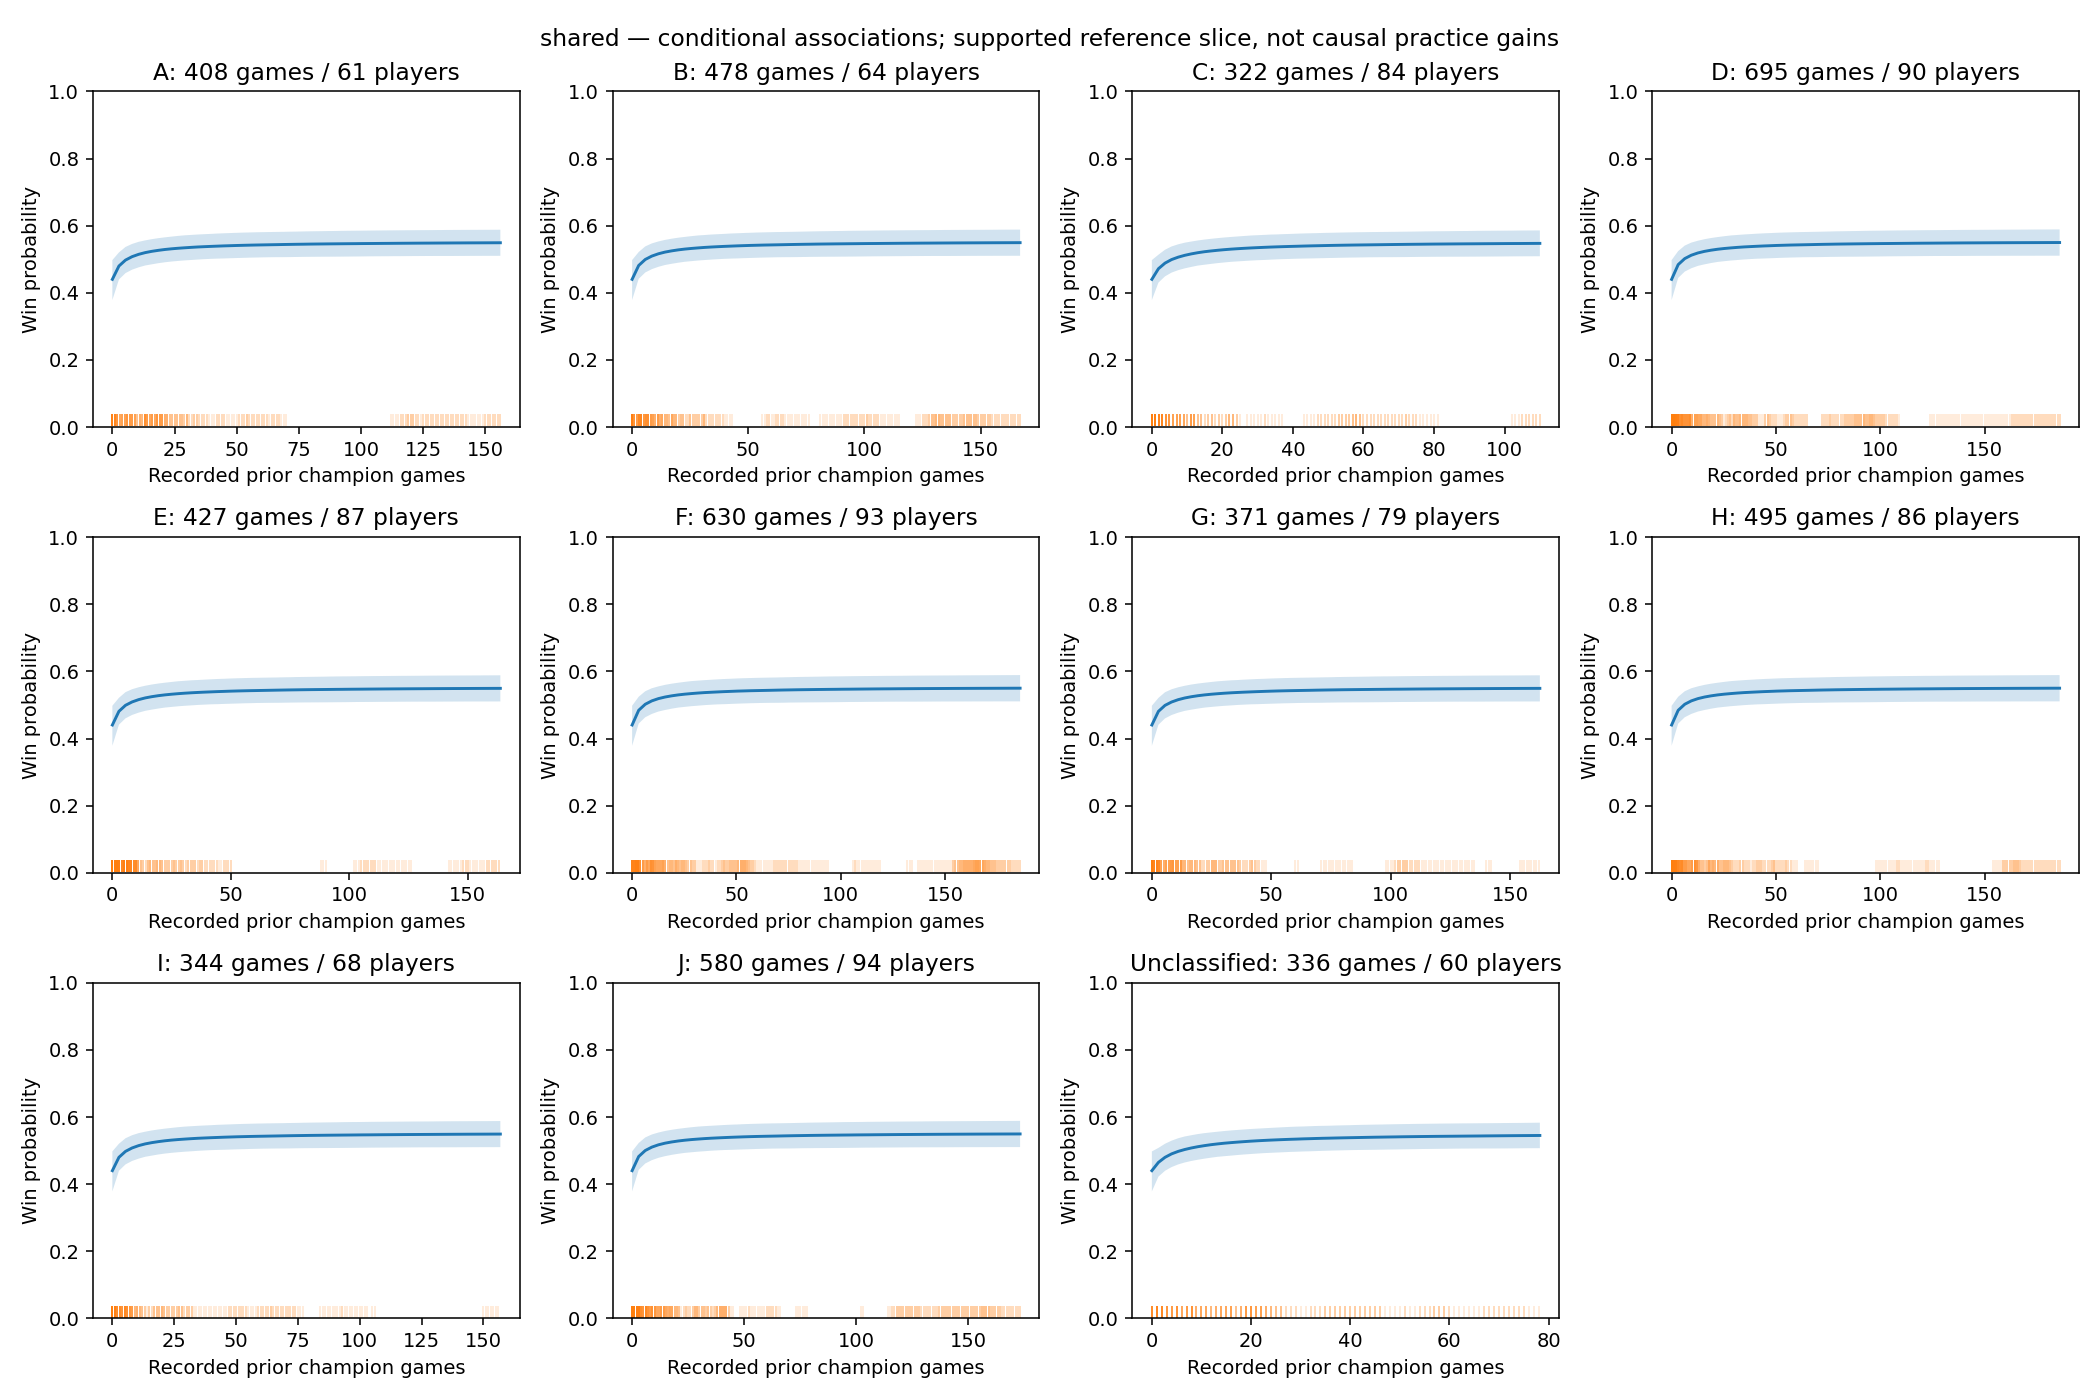

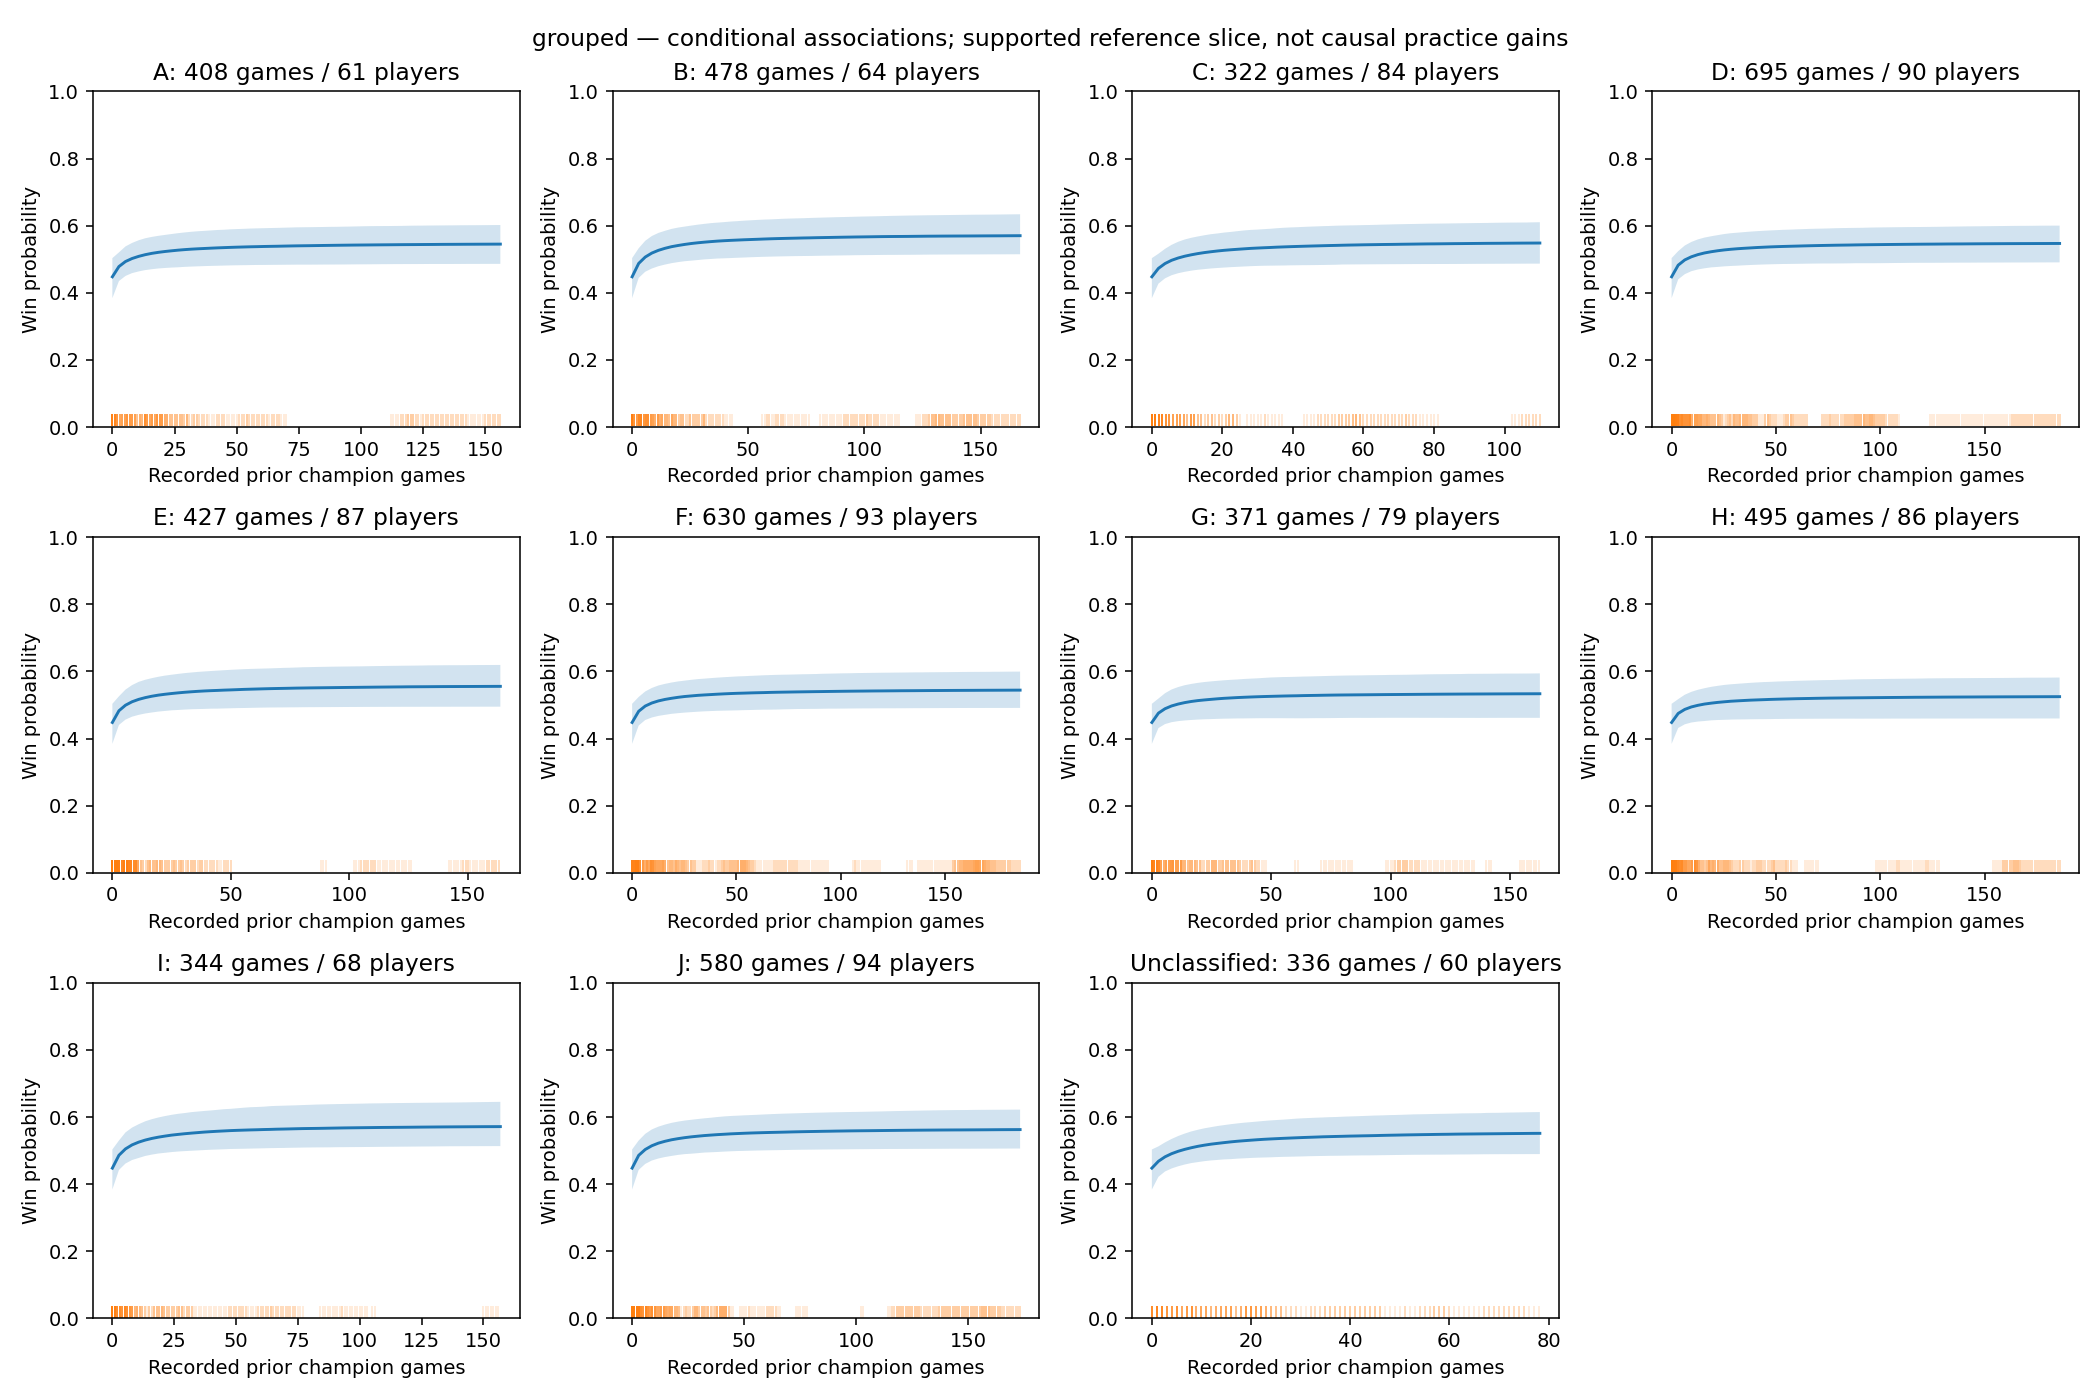

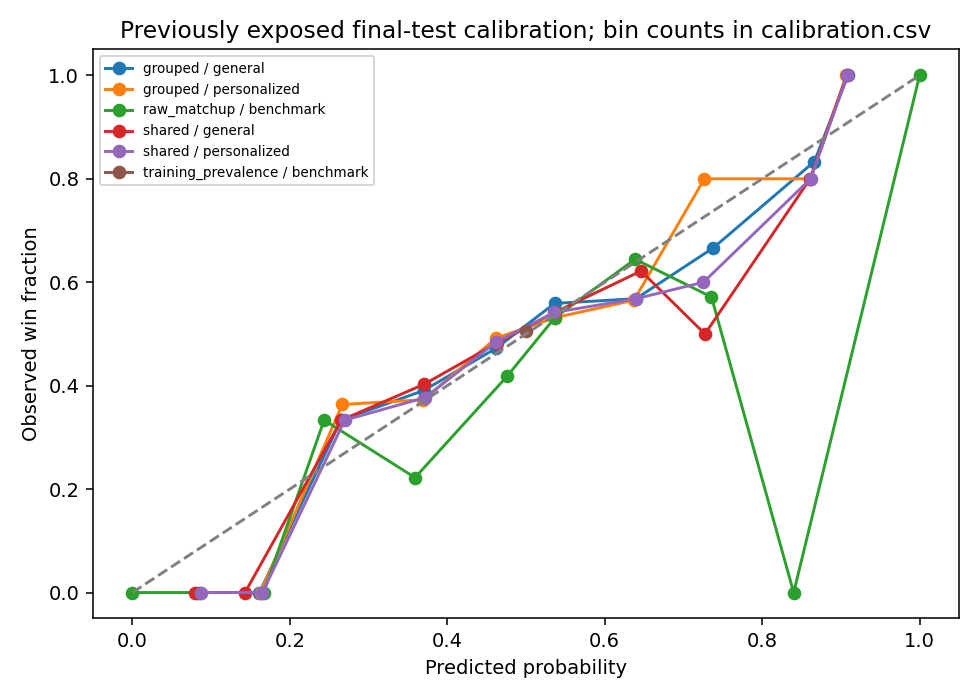

pairs  point_preference_changed  personalized_uncertain  \
model   reference                                                            
grouped main        5752                  0.020341                0.936370   
        played      6343                  0.018918                0.891692   
shared  main        5752                  0.024861                0.928373   
        played      6343                  0.015450                0.883336   

                   alternative_sparse  
model   reference                      
grouped main                 0.930981  
        played               0.917074  
shared  main                 0.930981  
        played               0.917074

,model,reference,reference_experience,alternative_experience,raw_matchup_advantage_pp,difference_pp,low_pp,high_pp,probability_alternative_higher,preference,reference_sparse_training_support,alternative_sparse_training_support
12095,shared,played,7,1,4.21,-1.015976,-12.248234,10.495355,0.421667,Uncertain,True,True
12096,shared,main,70,7,6.81,5.115770,-5.282811,15.466663,0.846042,Uncertain,False,True
12097,shared,main,70,1,11.02,4.099794,-6.710325,15.250078,0.766458,Uncertain,False,True
12098,shared,main,70,1,4.94,-2.329353,-13.130345,8.656151,0.328750,Uncertain,False,True
12099,shared,main,70,5,3.33,-1.706574,-12.456242,8.876143,0.362292,Uncertain,False,True
12100,shared,main,70,4,2.70,-1.856034,-11.830486,8.608300,0.348125,Uncertain,False,True


• Recorded prior champion games are season/history-bounded all-role counts, not lifetime experience or mastery points.
• External groups use the workbook's patch 13.7, mostly Gold, EUW/NA/KR study; transport to this cohort is an assumption.
• External gains define groups only and are never added to a predicted probability; J may have a nonzero fitted slope.
• Full-patch matchup rates make this retrospective benchmark-assisted evaluation, not leakage-free prospective prediction.
• Earlier completed held-out games may update saved pregame histories; held-out outcomes never refit parameters.
• General predictions set player and player–champion intercepts to zero; they do not marginalize those effects.
• Unseen player/champion combinations use population distributions with uncertainty, not invented fitted intercepts.
• Observational comparisons do not establish that switching picks or additional practice would cause a win.
• Posterior intervals condition on external benchmarks, group assig

In [7]:
if report is not None:
    print('Saved training matchup SD:',results['shared']['design'].scale[0])
    for name in ['posterior_summary','group_amplitude_summary','cohort_support_comparison','cohort_association_comparison','cohort_performance_comparison','cohort_recommendation_comparison']:
        print(name);display(pd.read_csv(OUTPUT_PATH/(name+'.csv')))
    for name in ['shared_group_curves','grouped_group_curves','test_calibration']:
        display(Image(filename=str(OUTPUT_PATH/'figures'/(name+'.png'))))
    paired=pd.read_parquet(OUTPUT_PATH/'paired_recommendations.parquet')
    pair_key=['model','puuid','match_id','reference','reference_champion_id','alternative_champion_id']
    compared=paired.loc[paired['mode'].eq('general')].merge(paired.loc[paired['mode'].eq('personalized')],on=pair_key,suffixes=('_reference','_personalized'),validate='one_to_one')
    compared['point_changed']=compared.point_prefers_alternative_reference.ne(compared.point_prefers_alternative_personalized)
    display(compared.groupby(['model','reference']).agg(pairs=('point_changed','size'),point_preference_changed=('point_changed','mean'),
        personalized_uncertain=('preference_personalized',lambda s:s.eq('Uncertain').mean()),alternative_sparse=('alternative_sparse_training_support_personalized','mean')))
    display(paired.loc[paired['mode'].eq('personalized'),['model','reference','reference_experience','alternative_experience','raw_matchup_advantage_pp',
        'difference_pp','low_pp','high_pp','probability_alternative_higher','preference','reference_sparse_training_support','alternative_sparse_training_support']].head(6))
for limit in master.LIMITS:print('•',limit)


## 7. Completed Master-cohort findings — 2026-10-28

**What ran.** Offline hash/provenance audits and independent expanding-history reconstruction; preparation-only execution; training-only EDA; two smoke models with verified movement/shapes/cache reuse; both full exact Pyro 1.9.2 NUTS fits; validation review followed by exposed test scoring; posterior curves, paired reference-player/personalized recommendations and read-only broad-cohort comparisons. Full settings remain four sequential chains/model, 600 warmup + 1,200 retained draws, target .9, depth 9 and one torch thread. No collection, broad refit, cohort pooling, or test-driven tuning ran.

**Actual data.** 200 selected legacy Master-labeled seeds; 15 have no target games. There are 185 target players, **7,238 player-games / 6,806 unique matches**, with 29,889 initial-history rows. Eleven target rows are excluded (5 incomplete-history, 4 unidentified opponents, 2 unpublished Global rates), and 27 boundary rows are purged. The retained analysis has **184 players / 7,200 player-games**: train **5,086 / 177 players / 4,746 matches**, validation **1,049 / 128 / 1,005**, test **1,065 / 127 / 1,019**. Source tables retain all original rows.

Actual initial-history depths among target players span 46–170, median 170; genuinely short complete histories are retained. Unplayed alternatives: 76,285 retained; 75,848 usable, 53 incomplete-history exclusions and 384 missing/unverified Global rates. Benchmarks are verified **Global Master+**, percentages divided by 100; NA is not substituted. All 477 Global pages succeeded; missing published opponent rows remain missing. NA has unresolved pages and is not used by these primary fits. No seed has dated rank verification. These labels therefore do not certify patch-period or collection-time Master membership.

**Diagnostics.** Both full models pass every unchanged gate; no rank coefficient was sampled. The only categorical reference in the Master likelihood is top role; the Master seed-rank constant is absorbed into the intercept.

| Model | Maximum R-hat | Minimum bulk ESS | Minimum tail ESS | Divergences | Minimum acceptance |
|---|---:|---:|---:|---:|---:|
| shared | 1.00884 | 3147 | 2296 | 0 | 1.00 |
| grouped | 1.00735 | 2534 | 2299 | 0 | 1.00 |

Tree-depth saturation and BFMI are unavailable from the wrapper. Stable sampling is not evidence of predictive usefulness.

**Evaluation on identical rows.** Lower losses are better; AUC is descriptive. Prior `hlr_modeling.ipynb` already examined these outcomes, and old `tradeoff_modeling.ipynb` examined validation. This assessment cannot be described as fresh confirmation. The new validation decision was recorded before the new test scoring, without changing either model.

| Split | Prediction | Log loss | Brier | AUC | Equal-player log loss |
|---|---|---:|---:|---:|---:|
| validation | training_prevalence | 0.693103 | 0.249978 | 0.500000 | 0.693052 |
| validation | raw_matchup | 0.680479 | 0.244478 | 0.563312 | 0.680106 |
| validation | shared / reference player | 0.686035 | 0.246899 | 0.554885 | 0.689254 |
| validation | shared / personalized | 0.685916 | 0.246846 | 0.553557 | 0.689231 |
| validation | grouped / reference player | 0.685969 | 0.246893 | 0.554232 | 0.689319 |
| validation | grouped / personalized | 0.685938 | 0.246883 | 0.553069 | 0.689302 |
| test | training_prevalence | 0.693139 | 0.249996 | 0.500000 | 0.693126 |
| test | raw_matchup | 0.680448 | 0.244709 | 0.561421 | 0.684760 |
| test | shared / reference player | 0.681771 | 0.244924 | 0.565370 | 0.692708 |
| test | shared / personalized | 0.681820 | 0.244952 | 0.562470 | 0.692047 |
| test | grouped / reference player | 0.681516 | 0.244812 | 0.566678 | 0.692436 |
| test | grouped / personalized | 0.681676 | 0.244893 | 0.564040 | 0.691848 |

Shared remains the prespecified primary, grouped secondary. Both beat the constant training-prevalence benchmark on game-weighted test losses, but **neither beats raw-matchup log loss or Brier**. The raw benchmark also has substantially lower equal-player test loss. Grouped has a small numerical test gain over shared (.00026 reference-player log loss; .00014 personalized), with mixed validation differences. This is not a demonstrated robust grouping benefit. Personalization slightly worsens game-weighted test losses/AUC but improves equal-player losses, so its apparent benefit is weighting-sensitive. No independent-row significance test or fresh replication is supplied. Calibration bins/plot are saved; extreme bins have few games. The raw rates cover the full patch and can overlap the evaluated games, so their observed advantage is retrospective benchmark-assisted performance, not prospective deployment evidence.

**Posterior associations and units.** The primary experience amplitude is **.458 [.232, .694] log-odds**; k is **5.3 [1.5, 28.8] recorded games** at half that asymptotic amplitude. Grouped common amplitude is **.445 [.213, .683]**, k **6.9 [1.8, 41.9]**. Saturation appears earlier than in the separate broad fit, but its bend remains uncertain and this is not evidence that Master players learn faster. The primary raw-matchup coefficient is **.333 [.265, .407] log-odds per training SD of .073677 probability (7.3677 raw pp)**, or **.090 [.072, .110] log-odds per +2 raw pp**. These are not probability-point gains. Player/PC/champion scale medians are .111/.102/.088 log-odds, with 95% intervals [.046,.200]/[.046,.197]/[.036,.162]. Scale and k positivity is structural, not a sign test.

Total group amplitudes are reconstructed with the saved zero-sum contrast basis. G/H still include negative amplitudes in their marginal 95% intervals; there is no forced workbook ordering. Of 55 paired within-posterior group contrasts, **0** have an unadjusted 95% interval excluding zero. A−J is **-0.064 [-0.397, 0.187] log-odds**, P(A>J)=0.289. This uses paired differences, not marginal-interval overlap. Curves condition on historical champion WR and the other covariates, so they do not estimate the total causal benefit of practice. Training high-experience coverage is only 4–11 players at n≥100 for most groups, six for A/J, and zero for Unclassified; the existing curves respect group support/context caps.

**Personalization and recommendations.** Shared comparisons cover **6,343 played-pick pairs / 924 targets / 123 players**, and **5,752 main pairs / 741 targets / 117 players**. Personalization changes 1.55%/2.49% of point preferences; 88.33%/92.84% of personalized paired intervals still include zero (grouped: 89.17%/93.64%). About 91.7%/93.1% of alternatives have sparse training support under the stated flags. Median personalized interval widths are about 21.4/21.5 probability points. The likelihood has 1,388 player–champion pairs, median one training appearance; 55.5% appear once and 82.9% fewer than five times. This is not first-time champion use: recorded history counts and likelihood observations differ. Reference-player effects are zero, not population averages; unseen identities retain pooled uncertainty. Neither played nor main paired preferences justify causal switching claims, and no unplayed pick receives an observed outcome.

**Separate-cohort comparison.** Master has 5,086 training rows from 177 players versus broad 3,907 from 265; both have median one training game per PC, though Master has more repeat outcomes and high-experience support (65 versus 37 players at n≥100). Both shared amplitudes are positive and similar in point magnitude (.458 versus .443); Master k has a lower point estimate (5.3 versus 28.9). The common +2-raw-pp matchup coefficient is .090 versus .060 log-odds. These are separate conditional estimates, not a formal test of rank differences; differing intervals/significance do not establish an interaction. Master recommendations are less often uncertain than broad (~88–94% versus ~98–99% personalized), but most remain uncertain. Broad test loss is near the constant benchmark; raw exact-tier rates have worse log loss despite slightly better Brier/AUC. Master models beat the constant but not their raw Master+ benchmark on losses. Neither comparison isolates experience’s incremental predictive value without an ablation, which was not fitted here.

**Pooling readiness and remaining limits.** The feature definitions, workbook groups, queue/patch, UTC boundaries and held-out freezing rules are structurally comparable. There are **zero shared players, 31 shared matches, zero duplicate player-match rows**; shared matches must remain together. A confirmatory pooled rank-interaction analysis is **not ready**: Master rank evidence is undated, broad ranks are collection-time rather than verified patch-period ranks, benchmark tiers differ (Master+ versus exact tiers), and both test sets have prior exposure. Benchmark harmonization/rank evidence and a dependence-aware pooled design must be settled later. Role labels are inferred from completed-match play, not verified pregame lane intent. External benchmark/study transport uncertainty is outside these posterior intervals. No computational task remains pending; these inferential limitations remain.

All outputs are separate under `master_cohort_mastery_v1/20261028T214327398991Z_4beeb7d4/`. Broad and prior Master notebooks/artifacts were verified unchanged. To resume/reproduce with existing caches from the repository root: `.venv-modeling/bin/python -u hlr_model/data/analyses/master_cohort_mastery_v1/20261028T214327398991Z_4beeb7d4/execute_notebook.py hlr_model/master_cohort_modeling.ipynb`. Select the project `riot-modeling` kernel (JUPYTER_PATH under `.venv-modeling/share/jupyter`); the notebook retains all sources/settings/chain manifests and checksummed evaluation caches.


## 8. Actual main picks: one selected alternative per game

**David's question:** when the player actually picked their recorded main, does the saved shared model favor it or a familiar, better-matchup alternative, and does personalization change the decision?

This section is independently runnable. It reads verified completed manifests, diagnostic status, prepared test rows and **saved shared-model main-reference predictions only**. It does not call collection, fitting, model selection, posterior prediction or predictive evaluation. Earlier cells and outputs are preserved.

Master labels are undated/unverified, benchmarks are Global **Master+**, and prior notebooks already examined validation/test outcomes. All rates cover the full patch: this remains retrospective benchmark-assisted reporting of modeled preferences. Cohorts remain separate.

**Scope of these preserved results: familiar alternatives with prior same-role play. The 17.6% Master / 2.1% broad figures are familiar-only; see the appended expanded-candidate section for the broader question.**

In [2]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display,Image
_report_start=Path.cwd().resolve()
_report_root=next(p for p in [_report_start,*_report_start.parents]
                  if (p/'hlr_model/main_pick_decision_report.py').is_file())
if str(_report_root) not in sys.path:sys.path.insert(0,str(_report_root))
from hlr_model import main_pick_decision_report as main_pick_report
MAIN_PICK_REPORT=main_pick_report.build_report(_report_root,'Master')
print('Verified saved shared fit, full diagnostic gate and input hashes; no inference, prediction or evaluation ran.')
print('New report directory:',MAIN_PICK_REPORT['output'])


Verified saved shared fit, full diagnostic gate and input hashes; no inference, prediction or evaluation ran.
New report directory: /Users/minhho-hoang/Documents/riot_proj/riot-game-prediction/hlr_model/data/analyses/master_cohort_mastery_v1/20261028T214327398991Z_4beeb7d4/reports/main_pick_decisions_v1


**Coverage and denominator.** “Retained test” means every prepared row with `split == 'test'`, including unusable-benchmark rows; original scored-row counts are shown separately. This keeps coverage losses visible rather than silently starting from the already filtered evaluation subset. A player-game is one player/match row, so a shared match can contribute more than one player-game.

Main remains the champion with the most strictly prior all-role games, smallest ID on ties; there is **no OTP-share threshold**. The last funnel stage requires at least one previously played same-role alternative with usable own history/benchmark and a strictly higher raw matchup rate. The existing saved main-reference predictions also require the main to have prior same-role support. Recorded eligibility does not verify draft availability.

In [3]:
_report_summary=MAIN_PICK_REPORT['summary']
display(_report_summary.loc[_report_summary.section.eq('coverage'),
    ['measure','count','players','unique_matches','denominator','percent']].set_index('measure').style.format({'percent':'{:.1f}%'}))
display(_report_summary.loc[_report_summary.section.eq('context') & _report_summary['mode'].eq('Both modes'),
    ['measure','count','players','unique_matches']].set_index('measure'))
print('Disjoint reasons for losing main-pick games after checking the main benchmark:')
display(_report_summary.loc[_report_summary.section.eq('coverage_loss'),
    ['measure','count','players','denominator','percent']].set_index('measure').style.format({'percent':'{:.1f}%'}))


,count,players,unique_matches,denominator,percent
measure,,,,,
Retained chronological test player-games,1067,128,1021,1067,100.0%
Identifiable pregame main,1067,128,1021,1067,100.0%
Actual main-pick games,392,91,387,1067,36.7%
Main-pick games with usable main benchmark,392,91,387,1067,36.7%
Main-pick games with at least one eligible better-matchup alternative,324,85,321,1067,30.4%


,count,players,unique_matches
measure,,,
Test rows used in original predictive evaluation,1065,127,1019


Disjoint reasons for losing main-pick games after checking the main benchmark:


,count,players,denominator,percent
measure,,,,
Main history/features unusable,0,0,392,0.0%
Main lacks prior same-role support required by saved main-reference comparisons,3,3,392,0.8%
No recorded same-role alternative,18,4,392,4.6%
No usable same-role alternative benchmark/history,0,0,392,0.0%
No usable alternative with strictly better raw matchup,47,25,392,12.0%


**One alternative per game and mode.** Among the same eligible better-raw-matchup alternatives, select the largest **saved posterior mean win probability**, breaking exact ties by smallest champion ID. Reference-player and personalized modes select separately. Every selected row retains its own count, Beta(1,1) historical WR, group and raw benchmark. No observed outcome is assigned to an alternative.

Alternative favored means paired 95% interval entirely above zero; main favored over selected alternative means entirely below zero; uncertain includes zero. These are **selected-comparison intervals**, not simultaneous or selection-adjusted guarantees. “Main favored” concerns that mode's selected alternative, not proof that every eligible alternative is inferior.

Denominator: 324 main-pick player-games with at least one eligible better-matchup alternative, in each mode.


measure,Alternative favored,Main favored over selected alternative,Uncertain,Alternative has strictly higher mean prediction
mode,,,,
Reference player,80 (24.7%),1 (0.3%),243 (75.0%),207 (63.9%)
Personalized,57 (17.6%),0 (0.0%),267 (82.4%),209 (64.5%)


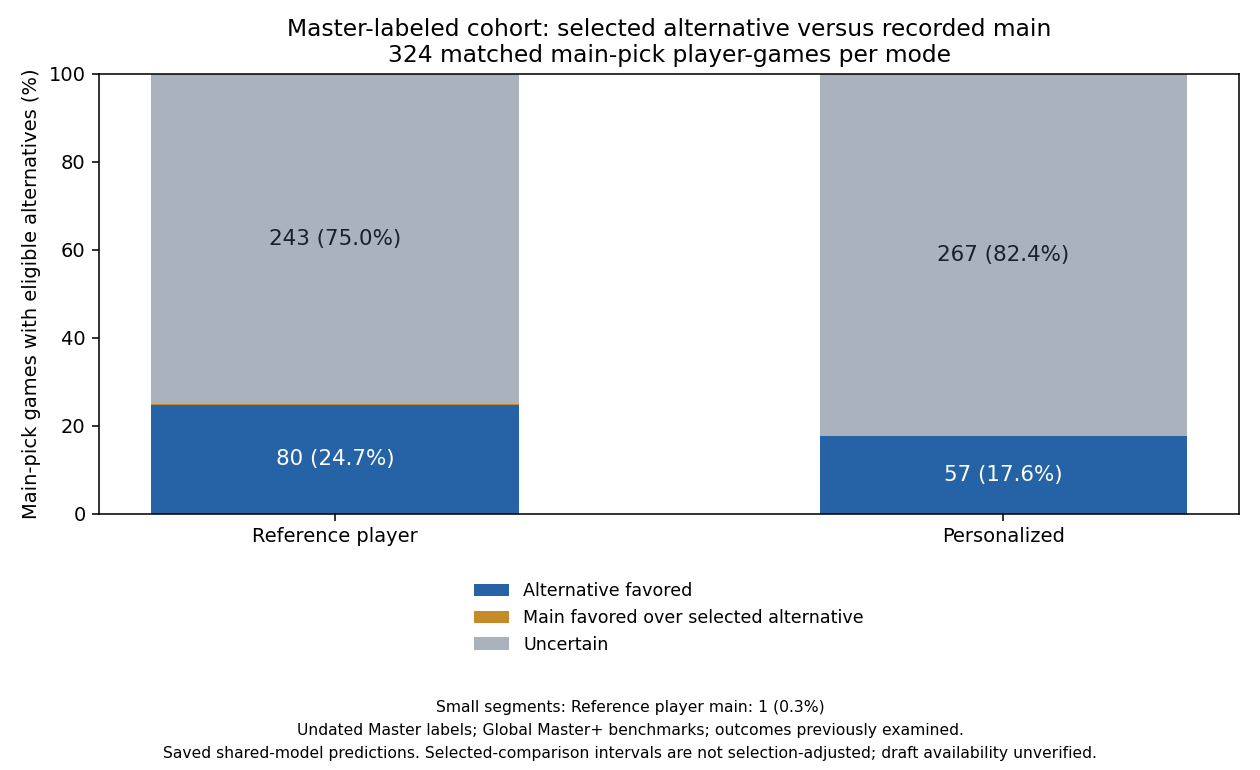

In [4]:
_frequency=_report_summary.loc[_report_summary.section.isin(['classification','point_preference'])].copy()
_frequency['games (percent)']=[f'{r.count} ({r.percent:.1f}%)' for r in _frequency.itertuples()]
_compact_frequency=_frequency.pivot(index='mode',columns='measure',values='games (percent)').reindex(
    index=['Reference player','Personalized'],columns=[*main_pick_report.CATEGORIES,'Alternative has strictly higher mean prediction'])
_report_denominator=int(_frequency.denominator.iloc[0])
print(f'Denominator: {_report_denominator} main-pick player-games with at least one eligible better-matchup alternative, in each mode.')
display(_compact_frequency)
display(Image(filename=str(MAIN_PICK_REPORT['output']/'classifications.png')))


**Different meanings of “changed decision.”** Report separately: selected-alternative champion changed; the highest-mean champion among main and the selected alternative changed; the point preference switched between staying and leaving main; and the paired-uncertainty category changed. The two modes are matched on exactly the same player-games. A different best alternative need not change the decision to leave the main.

Exact main-versus-alternative mean ties use smallest champion ID, with tie counts shown below. “Higher mean” remains a strict comparison. Reference-player mode still uses that player's recorded histories; it omits learned player/player–champion adjustments and is **not a population-average prediction**.

In [5]:
display(_report_summary.loc[_report_summary.section.eq('personalization_change'),
    ['measure','count','denominator','percent','players']].set_index('measure').style.format({'percent':'{:.2f}%'}))
display(_report_summary.loc[_report_summary.section.eq('context') & ~_report_summary['mode'].eq('Both modes'),
    ['mode','measure','count']].set_index('mode'))
print('Game-level decisions retain player/match keys, own pick features, saved probabilities/paired intervals, and training-support flags:')
print(MAIN_PICK_REPORT['output']/'game_level_decisions.parquet')


,count,denominator,percent,players
measure,,,,
Selected alternative changed,3,324,0.93%,3
Highest-mean choice champion changed,6,324,1.85%,5
Point preference switched between main and any alternative,4,324,1.23%,3
Uncertainty classification changed,24,324,7.41%,21


,measure,count
mode,,
Personalized,Exact main/selected-alternative mean ties,0
Reference player,Exact main/selected-alternative mean ties,0


Game-level decisions retain player/match keys, own pick features, saved probabilities/paired intervals, and training-support flags:
/Users/minhho-hoang/Documents/riot_proj/riot-game-prediction/hlr_model/data/analyses/master_cohort_mastery_v1/20261028T214327398991Z_4beeb7d4/reports/main_pick_decisions_v1/game_level_decisions.parquet


**Three illustrative games, where available.** In category order alternative-favored, main-favored, then uncertain, take the first chronological **distinct** game exhibiting that classification in **either** mode; skip games already shown and break time ties by player/match keys. Show both modes side by side, and explicitly name which mode supplies the example's category. This permits a reference-only main-favored example without pretending a personalized main-favored game exists. Missing categories are stated. Player labels are anonymous; examples are illustrative and were not selected using observed wins or large modeled gains.

In [6]:
main_pick_report.display_examples(MAIN_PICK_REPORT)


Illustrative Alternative favored: Player 059, 2026-10-05 01:32:18.312000+00:00, adc; category present in: Reference player.


,Reference player,Personalized
Main,Caitlyn (51),Caitlyn (51)
Selected alternative,Senna (235),Senna (235)
Eligible better-matchup alternatives,3,3
Recorded games: main / alternative,114 / 24,114 / 24
"Historical Beta(1,1) WR: main / alternative",51.7% / 53.8%,51.7% / 53.8%
Group: main / alternative,E / G,E / G
Raw matchup: main / alternative,52.13% / 60.00%,52.13% / 60.00%
Predicted probability: main / alternative,52.57% / 60.13%,52.20% / 59.83%
Alternative − main (probability pp),"+7.55 [+0.99, +14.27]","+7.64 [-2.45, +18.12]"
P(alternative higher),0.986,0.929


Illustrative Main favored over selected alternative: Player 107, 2026-10-07 03:19:52.249000+00:00, adc; category present in: Reference player.


,Reference player,Personalized
Main,Draven (119),Draven (119)
Selected alternative,Twitch (29),Twitch (29)
Eligible better-matchup alternatives,1,1
Recorded games: main / alternative,272 / 1,272 / 1
"Historical Beta(1,1) WR: main / alternative",54.4% / 33.3%,54.4% / 33.3%
Group: main / alternative,D / D,D / D
Raw matchup: main / alternative,52.33% / 54.51%,52.33% / 54.51%
Predicted probability: main / alternative,51.85% / 43.41%,49.37% / 41.00%
Alternative − main (probability pp),"-8.44 [-16.63, -0.94]","-8.37 [-18.44, +2.08]"
P(alternative higher),0.015,0.051


Illustrative Uncertain: Player 081, 2026-10-05 01:50:01.915000+00:00, mid; category present in: Personalized / Reference player.


,Reference player,Personalized
Main,Zed (238),Zed (238)
Selected alternative,Vladimir (8),Vladimir (8)
Eligible better-matchup alternatives,3,3
Recorded games: main / alternative,105 / 6,105 / 6
"Historical Beta(1,1) WR: main / alternative",52.3% / 50.0%,52.3% / 50.0%
Group: main / alternative,B / D,B / D
Raw matchup: main / alternative,49.90% / 55.12%,49.90% / 55.12%
Predicted probability: main / alternative,45.95% / 47.53%,44.68% / 46.70%
Alternative − main (probability pp),"+1.58 [-5.21, +8.51]","+2.02 [-7.88, +12.13]"
P(alternative higher),0.687,0.652


No personalized game is classified as main favored over selected alternative; any displayed example in that category is explicitly reference-player only.


These modeled preferences do not measure observed win rates on unplayed champions or proven gains from switching. Sparse training support is flagged in the saved decisions/examples. Selecting the largest estimated alternative can overstate certainty without selection adjustment; many intervals remain uncertain. The only new artifacts are **game-level decisions**, one **summary CSV**, and one **classification chart**, in the dedicated report subfolder. Existing fit/evaluation artifacts are unchanged.

## Expanded published-matchup candidates — separate from familiar-only results

These exploratory reports reuse the completed **shared** models. Candidates need a verified Global patch-16.19 same-role benchmark against the known opponent, strictly above the main’s raw benchmark. Prior champion/same-role play is not required, and observed main picks do not need prior same-role support. The main and known opponent are excluded from alternatives. Broad retains exact Bronze–Diamond tiers; Master retains Master+ benchmarks and unverified legacy rank labels.

**Two distinct rules:** highest raw matchup benchmark, and highest posterior mean model prediction (selected separately by mode). Ties use the smallest champion ID. All-role history is reconstructed strictly before kickoff, including play in other roles; a genuine zero gets games/wins 0 and Beta(1,1) WR .5, while total player history, fitted coefficients, matchup input and champion baseline remain intact. Paired predictions reuse the saved draws and identity-stable pooled distributions for unseen identities.

The earlier **17.6% Master / 2.1% broad** results and their original outputs are **familiar-only** comparisons restricted to prior same-role alternatives. New outputs live in `reports/expanded_published_candidates_v1/`. Unavailable/unpublished rates remain missing, sparse flags are retained without a minimum-game threshold, and games without eligible alternatives are not confirmed main preferences.


In [1]:
from pathlib import Path
import sys
_expanded_start=Path.cwd().resolve()
_expanded_project=next(p for p in [_expanded_start,*_expanded_start.parents] if (p/'hlr_model/expanded_main_pick_report.py').is_file())
if str(_expanded_project) not in sys.path:sys.path.insert(0,str(_expanded_project))
from hlr_model import expanded_main_pick_report as expanded_report
EXPANDED_REPORT_PATH=expanded_report.display_report(_expanded_project,'Master')

### Master — expanded eligible published matchup candidates

Shared models and 4,800 saved posterior draws; no refit or predictive evaluation. Highest raw matchup and highest model prediction are separate rules; smallest champion ID breaks ties. Reference-player predictions set player/player–champion effects to zero and are not population averages.

**Matchup-table coverage:** {'unavailable': 22, 'verified': 843} of 865 required pages. All pages attempted: True. Unverified, unavailable and unpublished rates stay missing; no minimum-game filter is imposed. Sparse n<100 flags are retained.

measure,count,denominator,players,unique_matches
Total actual main-pick games,392,392,91,387
Main-pick games with usable main features/benchmarks,392,392,91,387
Games with eligible published better-matchup alternatives,387,392,91,382
Usable main games without an eligible published alternative,5,392,5,5
No eligible published better-matchup alternative (not a confirmed main preference),5,392,5,5


,benchmark_status,candidate_rows,player_games,players
0,eligible_better_matchup,24331,387,91
1,not_published_in_table,11852,392,91
2,published_not_strictly_better,29498,392,91
3,unavailable,1351,255,67


...

#### Master — actual saved examples (personalized; best baseline matchup)

**Zero-history alternative favored:** 2026-10-05 01:32 UTC, adc, Caitlyn → Annie. Recorded champion games 114 → 0; raw matchup 52.13% → 100.00% (candidate benchmark n=5). Modeled win probability 52.20% → 85.81%; alternative − main **+33.62 pp [+22.42, +44.67]** (95% credible interval); **Alternative favored**.

**Main favored over zero-history alternative:** no example in these completed comparisons.

**Uncertain comparison:** no example in these completed comparisons.

Zero means zero in recorded Season 16 history, not lifetime experience. All-role counts, Beta(1,1) historical WR and total prior history are reconstructed strictly before kickoff; zero experience does not zero the learned coefficient, matchup benchmark or champion baseline. Unseen identities retain identity-stable pooled predictive uncertainty. These are retrospective exploratory conditional comparisons. Unplayed outcomes and draft availability are unknown; selected-comparison credible intervals are not selection-adjusted and omit external benchmark sampling/transport error.